# Figure 4 D&E: chest visibility and trial-3 duration


In [1]:
import math
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

fig_folder = "../Figure_paper/"
Path(fig_folder).mkdir(parents=True, exist_ok=True)

## Load inputs and calculate the visibility distance

In [2]:
all_conditions = pd.read_csv('../Combined_data/all_conditions.csv', index_col=0)
DATA = pd.read_csv('../Combined_data/traj_df_2025.csv', low_memory=True, index_col=0)

C:\Users\chado\AppData\Local\Temp\ipykernel_22844\1102273493.py:2: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  DATA = pd.read_csv('../Combined_data/traj_df_2025.csv', low_memory=True, index_col=0)


In [3]:
# define distance maximum based on walked trajectory when chest barely visible

traj_distance = pd.read_csv('../Combined_data/test_trajectory.csv',low_memory=False)

In [4]:
def Euclidean_Dist(df1, df2, cols=['x','y']):
    
    return np.linalg.norm(df1[cols].values - df2[cols].values,
                   axis=1)

In [5]:
# define distance maximum before out of sight. 
extrem_x = traj_distance.pos_x.max()
extrem_y = traj_distance.pos_z.min()

extreme_pt = pd.Series(data={'x': extrem_x,'y':extrem_y}).to_frame().transpose()
chest_pos = all_conditions.loc[(all_conditions.scale == 'S1')&(all_conditions.cond == 'C1')&(all_conditions.node == 10)]

distance_th = Euclidean_Dist(extreme_pt, chest_pos, cols=['x','y'])

In [6]:
# camera field of view
import math
VFOV = 60  # Vertical Field of View in degrees
aspect_ratio = 16 / 9  # Aspect Ratio of most screen ... it was set to free aspect !! 

# Convert VFOV to radians
VFOV_rad = math.radians(VFOV / 2)

# Compute HFOV
HFOV = 2 * math.degrees(math.atan(math.tan(VFOV_rad) * aspect_ratio))
HFOV

91.49284451967722

## Reconstruct the sampled trial-3 positions

Keep the original ordering and sampling steps: the Unity output and sampled player rotations are paired by row.

In [7]:
DATA3 = DATA.loc[DATA.trial_num == 3]

In [8]:
player = pd.DataFrame()
scaling = [int(25/2),int(37/2),int(75/2),int(150/2),int(225/2)]
## 
for (scale,cond),df in DATA3.groupby(['scale','cond']):
    scaling_access = int(re.search(r'\d+', scale).group()) -1 
    sampling = scaling[scaling_access]
    traj = df[::sampling]
    player = pd.concat([player,traj],ignore_index =True,axis = 0)

In [9]:
player = player.rename(columns={"pos_x": "x", "pos_y": "y", "pos_z": "z"})

## Load Unity visibility output and chest coordinates

In [10]:
all_conditions = pd.read_csv('../Combined_data/'+'all_conditions.csv',index_col = 0)
targets  = all_conditions.loc[all_conditions.node !=1]
targets['targetid']= targets.node.apply(lambda x : 'Node_'+ str(x))
targets['z'] =  1.25
targets = targets.rename(columns ={"x": "pos_x","y": "pos_y","z": "pos_z"})
targets = targets.rename(columns ={"pos_x": "x","pos_y": "z","pos_z": "y"})
targetsdf = targets
targetsdf['key'] = targetsdf["cond"] + "_" + targetsdf["scale"] 

# Selecting only the relevant columns
targetsdf = targetsdf.loc[:, ['targetid','x', 'y', 'z', 'key']]
targetsdf.head(2)

C:\Users\chado\AppData\Local\Temp\ipykernel_22844\3998928570.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  targets['targetid']= targets.node.apply(lambda x : 'Node_'+ str(x))
C:\Users\chado\AppData\Local\Temp\ipykernel_22844\3998928570.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  targets['z'] =  1.25


,targetid,x,y,z,key
1,Node_2,-12.666667,1.25,6.333333,C1_S1
2,Node_3,-17.333333,1.25,14.000000,C1_S1


In [11]:
output = pd.read_csv('../Combined_data/'+'raycast_game.csv')
output.playerID.nunique()

62

In [12]:
hitted = output.loc[:,['playerID', 'x', 'y', 'z', 'cond', 'scale','Node_2', 'Node_3',
       'Node_4', 'Node_5', 'Node_6', 'Node_7', 'Node_8', 'Node_9', 'Node_10']]

In [13]:
hitted['rot_y'] = player['rot_y']

## Combine distance, field of view, and occlusion

In [14]:
# make code clearner :
# create a boolean dataframe for the distance of all nodes
max_view_distance = distance_th



#test = hitted.loc[hitted.playerID == 'Aigle']
#test = test.loc[(test.cond == 'C1') & (test.scale == 'S1')]
test = hitted.copy()
distance_df = pd.DataFrame(index = test.index,columns=['Node_2', 'Node_3', 'Node_4', 'Node_5', 
                                          'Node_6', 'Node_7', 'Node_8', 'Node_9', 'Node_10'])
in_view_df = pd.DataFrame(index = test.index,columns=['Node_2', 'Node_3', 'Node_4', 'Node_5', 
                                          'Node_6', 'Node_7', 'Node_8', 'Node_9', 'Node_10'])

# loop on node/chest to assign visibility to : 
for node in ['Node_2', 'Node_3', 'Node_4', 'Node_5','Node_6', 'Node_7', 'Node_8', 'Node_9', 'Node_10'] : 
    
    target_node = targets.loc[targets.targetid == node]
    
    df_node = test.copy()
    df_node = df_node.filter(['cond','scale','x','z','rot_y','playerID',node])
    df_node['targetid'] = node
    df_node = pd.merge(df_node, target_node, 
                       on=['targetid','cond','scale'],  # Merge on matching 'targetid'
                       how='left', 
                       suffixes=('_playerpos', '_target'))

                      
    Ppos = df_node.loc[:,['x_playerpos','z_playerpos']]
    Ppos = Ppos.rename(columns={"x_playerpos": "x", "z_playerpos": "z"})
    Tpos = df_node.loc[:,['x_target','z_target']]
    Tpos = Tpos.rename(columns={"x_target": "x", "z_target": "z"})
    to_object = Tpos.filter(['x','z']).values - Ppos.filter(['x','z']).values

    #to_object = to_object.flatten()
    distance  = np.linalg.norm(to_object, axis= 1)

    bool_dist = distance < max_view_distance

    distance_df[node] = bool_dist  # Simpler way
    
    # Normalize direction to object
    to_object_norm = to_object / distance[:, np.newaxis]
    #test['rot_y'] = 2
    view_direction = np.deg2rad(test.loc[:, ['rot_y']])
    view_direction_vector = np.column_stack([
    np.sin(view_direction.values.flatten()),  # x-component
    np.cos(view_direction.values.flatten())   # z-component
])

    
    # Compute dot product (element-wise)
    dot_product = np.einsum('ij,ij->i', view_direction_vector, to_object_norm)  

    # Ensure numerical stability
    dot_product = np.clip(dot_product, -1.0, 1.0)

    # Compute angles in degrees
    cross_product = (view_direction_vector[:, 0] * to_object_norm[:, 1] - 
                 view_direction_vector[:, 1] * to_object_norm[:, 0])

    angles = np.degrees(np.arctan2(cross_product, dot_product))
    # Check if within HFOV
    bool_inHFOV =  np.abs(angles)  < (HFOV  / 2)
    in_view_df[node] = bool_inHFOV

In [15]:
visible_df = hitted.loc[:, ['Node_2', 'Node_3', 'Node_4', 'Node_5', 
                                          'Node_6', 'Node_7', 'Node_8', 'Node_9', 'Node_10']]

## Trial-3 durations

In [16]:
time_df =DATA3.groupby(['cond', 'scale','ppid']).first()
def get_time_taken_sec(t):

    import time
    from datetime import datetime
        
    # Truncate the microseconds to 6 digits
    t = t[:-1]
    
    # Parse using datetime
    try :
        parsed_time = datetime.strptime(t, '%H:%M:%S.%f')
        # Calculate the total number of seconds
        seconds = parsed_time.hour * 3600 + parsed_time.minute * 60 + parsed_time.second + parsed_time.microsecond / 1e6
    except :
        print('error',t)
        parsed_time = datetime.strptime(t, '%H:%M:%S')
        seconds = parsed_time.hour * 3600 + parsed_time.minute * 60 + parsed_time.second 
    
    
    
    return seconds


time_df['time_seconds'] = time_df['time_taken'].apply(get_time_taken_sec)

## Final discussion figure

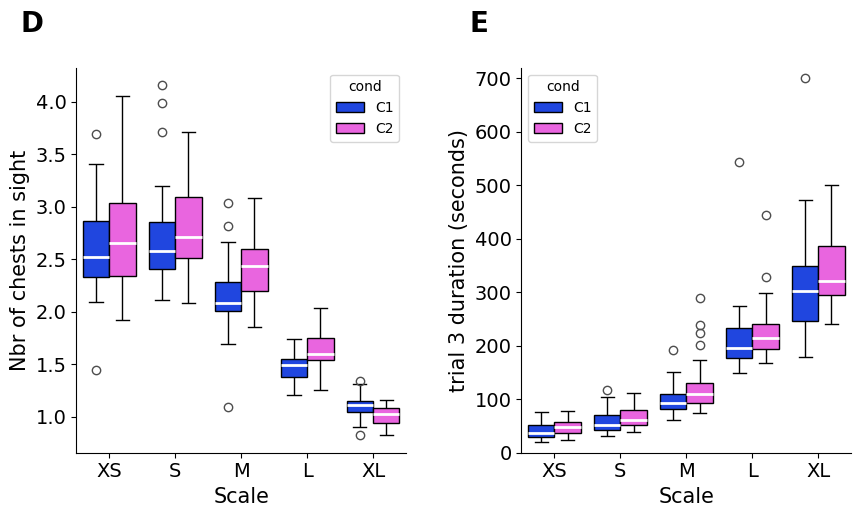

In [17]:
res =  visible_df *distance_df * in_view_df
res[['playerID', 'cond', 'scale']] = hitted[['playerID', 'cond', 'scale']]
res['total_in_sight']= res.loc[:, ['Node_2', 'Node_3', 'Node_4', 'Node_5', 
                                          'Node_6', 'Node_7', 'Node_8', 'Node_9', 'Node_10']].sum(axis=1)
res = res.loc[:,['playerID', 'cond', 'scale','total_in_sight']]



res = res.groupby(['playerID', 'cond', 'scale']).total_in_sight.mean().to_frame().reset_index()

fig, axs = plt.subplots(1, 2,figsize=(10,5))
ax = axs[0]
PROPS = {
    'boxprops':{'edgecolor':'black'},
    'medianprops':{'color':'white','linewidth':2},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
res['scale'] = pd.Categorical(res['scale'], categories = ['S1','S2','S3','S4','S5'], ordered=True)
sns.boxplot(data = res, x= 'scale', y='total_in_sight',hue ='cond',palette= ['#0033ff','#ff4ff1'],**PROPS,ax =ax)
sns.despine(bottom = False, left = False)
ax.set_xticks([0,1, 2,3,4], ['XS', 'S', 'M','L','XL'],fontsize= 15)
ax.set_xlabel('Scale',fontsize= 15)
ax.set_ylabel('Nbr of chests in sight',fontsize= 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.text(-0.1, 1.15, 'D', transform=ax.transAxes,
    fontsize=20, fontweight='bold', va='top', ha='right')


ax =axs[1]
res = time_df
sns.despine(bottom = False, left = False)
sns.boxplot(data = res, x= 'scale', y='time_seconds',hue ='cond',palette= ['#0033ff','#ff4ff1'],**PROPS, ax=ax)
plt.ylim(0,720)
ax.set_xlabel('Scale',fontsize= 15)
ax.set_ylabel('trial 3 duration (seconds)',fontsize= 15)
plt.xticks([0,1, 2,3,4], ['XS', 'S', 'M','L','XL'],fontsize= 15)

ax.text(-0.1, 1.15, 'E', transform=ax.transAxes,
    fontsize=20, fontweight='bold', va='top', ha='right')
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
plt.subplots_adjust( wspace=0.35)
#plt.savefig(fig_folder+'Fig4_Disucssion.png',dpi = 300)
#plt.savefig(fig_folder+'Fig4_Disucssion.svg')